---
title: "Comparing Local Models with Cloud AutoML"
subtitle: "Send the same customers to a cloud service and compare the probabilities"
jupyter: data-extraction-lesson
fig-width: 7
fig-height: 4.4
---

Chapters 5 and 6 left two kinds of information.

- The customer tables, and the quantities that split them into fit rows and test rows.
- The scores of those rows, and the campaign costs of the test rows.

The first objective is to gather both. Gemini is not used in this part. The fit table and the test table are what Gemini will receive. The comparison file is the test rows Gemini's scores will be added to.

Telco is the example. Another dataset uses the same capital-letter names and other paths.

The only `CLOUD_MODE` line to edit is in **Paths of the saved results**. Leave it as `"LOAD"`. `"LOAD"` reads files already on this computer. `"SAVE"` rebuilds those files on this computer. Neither value calls Google. A later cell repeats `"LOAD"` so that the final read does not rebuild. The only line that spends money is `START_PAID_TRAINING = True`, in the Gemini section.

::: callout-warning
## Money is spent only if you change that line

Rendering this file does not create a Google resource and does not start a training job.
:::

The telco comparison file already holds four scores: `p_logistic_tabular`, `p_logistic_text`, `p_automl_tabular` and `p_automl_text`. The two Gemini columns were saved from an earlier job. With `CLOUD_MODE` left at `"LOAD"` and `START_PAID_TRAINING` left at `False`, the cells read that file. A Google account is not required, and a render does not open a bucket.

Run the cells from top to bottom.

## Retrieval of the data

### Paths, columns, and the split

`use_course_example()` takes no input. It fills every capital-letter name with the telco example. It returns nothing. The assignments under it are the values the next functions read. Replace them for another dataset.

`TABULAR_FILE` is one row per customer. `TEXT_FILE` is one row per message. `ID_COLUMN` is the shared identifier. `TARGET_COLUMN` is the outcome. `POSITIVE_LABEL` is the label counted as a leave. In the example that label is `Yes`, later coded `1`.

`TEXT_COLUMN` is the message. `TEXT_ORDER_COLUMN` numbers one customer's messages. `TEXT_TYPE_COLUMN` names the kind of message. Set it to `""` when the file has no such column. `TEXT_FEATURE` is the name of the joined-text column this lesson will add. It is not a column of the source files.

`NUMERIC_FEATURES` and `CATEGORICAL_FEATURES` are the predictors. Do not put `ID_COLUMN` or `TARGET_COLUMN` in those lists.

`RANDOM_STATE` is the seed. `TEST_SIZE` is the share of customers held out of the fit. Chapter 5 used `42` and `0.25`. The same two numbers rebuild that split.

In [1]:
from pathlib import Path
import os
import sys

import pandas as pd

if not Path("data/raw/telco/telco_customers.csv").exists():
    os.chdir(Path("..").resolve())
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import python.workshop_automl as automl

automl.use_course_example()

automl.TABULAR_FILE = "data/raw/telco/telco_customers.csv"
automl.TEXT_FILE = "data/raw/telco/customer_communications.csv"
automl.ID_COLUMN = "customerID"
automl.TARGET_COLUMN = "Churn"
automl.POSITIVE_LABEL = "Yes"
automl.TEXT_COLUMN = "text"
automl.TEXT_ORDER_COLUMN = "text_index"
automl.TEXT_TYPE_COLUMN = "communication_type"
automl.TEXT_FEATURE = "customer_text"
automl.NUMERIC_FEATURES = ["tenure", "MonthlyCharges", "TotalCharges"]
automl.CATEGORICAL_FEATURES = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
]
automl.RANDOM_STATE = 42
automl.TEST_SIZE = 0.25
print("Working directory:", Path.cwd())
automl.active_settings()

Working directory: /Users/heuchennecedric/Documents/data-extraction-lesson


,Setting,Value
0,CLOUD_MODE,LOAD
1,TABULAR_FILE,data/raw/telco/telco_customers.csv
2,TEXT_FILE,data/raw/telco/customer_communications.csv
3,ID_COLUMN,customerID
4,TARGET_COLUMN,Churn
5,POSITIVE_LABEL,Yes
6,NUMERIC_FEATURES,"tenure, MonthlyCharges, TotalCharges"
7,CATEGORICAL_FEATURES,"gender, SeniorCitizen, Partner, Dependents, Ph..."
8,TEXT_FEATURE,customer_text
9,SPLIT_COLUMN,ml_split


### Gather the two files

`gather_sources()` takes no argument. It reads the paths and column names above. It sorts each customer's messages by `TEXT_ORDER_COLUMN`, joins them with a blank line, and stores the text in `customer_text` (`TEXT_FEATURE`). It returns one row per customer. It does not split. It does not call Google.

In [2]:
customers = automl.gather_sources()
shown = customers[[automl.ID_COLUMN, automl.TARGET_COLUMN, automl.TEXT_FEATURE]].head(2).copy()
shown[automl.TEXT_FEATURE] = (
    shown[automl.TEXT_FEATURE].str.replace("\n", " ", regex=False).str.slice(0, 80)
)
shown

Tabular file: data/raw/telco/telco_customers.csv
Text file: data/raw/telco/customer_communications.csv
Blank numeric values replaced with zero: 0


Gathered 7043 customers. Joined messages are in customer_text.


,customerID,Churn,customer_text
0,7590-VHVEG,No,**Customer:** I am calling about the service. ...
1,5575-GNVDE,No,**Agent:** Support here. I can help with the s...


### Separate fit rows and test rows

`separate_fit_test(customers)` takes the table just returned. It also reads `RANDOM_STATE`, `TEST_SIZE`, `ID_COLUMN`, `TARGET_COLUMN` and `POSITIVE_LABEL`. It returns two tables, `fit_table` and `test_table`. The split is stratified on the target. A row in `test_table` was not used to fit the Chapter 5 models. The row counts are the Chapter 5 counts when the seed and `TEST_SIZE` are unchanged.

`fit_table` is the table Gemini will train on. `test_table` is the table from which the scored customers are taken.

In [3]:
fit_table, test_table = automl.separate_fit_test(customers)
print("Fit rows:", len(fit_table))
print("Test rows:", len(test_table))

Training rows: 5282. Test rows: 1761. Random seed: 42.
Fit rows: 5282
Test rows: 1761


## Retrieval of the previous results

The scores and the campaign quantities are loaded here. `p1`, `cost` and `loss` are not model scores. Chapter 6 stored them for the test customers. They are loaded now because the comparison at the end uses them, and only them, as the campaign inputs.

### Paths of the saved results

`MODEL_ROWS_FILE` is the file Chapter 5 writes with `save_model_rows`. One row per customer. `role` is `fit` or `test`. `p_logistic_tabular` is the structured-fields score. `p_logistic_text` is the score that also uses the communications. `observed_outcome` is `1` or `0`. `MODEL_ROWS_ID_COLUMN` is the identifier column of that file. In the example it is `customer_id`. `ID_COLUMN` in the customer table is `customerID`. The two names are joined. The example path is `data/processed/telco/model_rows.csv`. Until that cell in Chapter 5 has been run, the file is absent. This lesson then uses `SAVED_PROBABILITY_FILE` for `p_logistic_text` and refits the tabular score when `CLOUD_MODE` is `"SAVE"`.

`SAVED_PROBABILITY_FILE` is the file `save_scores` (in Chapter 5) wrote for Chapter 6. In the example, `p0` (`SAVED_PROBABILITY_COLUMN`) is `p_logistic_text` on the test rows, and `observed_outcome` (`SAVED_OUTCOME_COLUMN`) is the same 0/1 outcome. `SAVED_PROBABILITY_ID` is the identifier column of that file.

`ECONOMICS_FILE` is Chapter 6's `POPULATION_FILE`. `ECONOMICS_P1_COLUMN` (`p1`) is the probability of staying if contacted. `ECONOMICS_COST_COLUMN` (`example_cost`) becomes `cost`. `ECONOMICS_LOSS_COLUMN` (`example_loss`) becomes `loss`. The file has the test customers, not the fit customers.

`HOLDOUT_VALIDATION_FRACTION = 0.5` keeps half of `test_table` for the comparison file. The other half is not scored. The comparison customers stay out of the training upload: the model Gemini keeps can be fit again on every uploaded row. `OUTPUT_DIR` is the folder of the files this lesson writes.

`OBSERVED_COLUMN` is the 0/1 column of the comparison file. `1` means `TARGET_COLUMN` equals `POSITIVE_LABEL`. In the example, `1` means `Churn` is `Yes`: the customer left. The functions read `OBSERVED_COLUMN`. Change `TARGET_COLUMN` in **Paths, columns, and the split** to use another outcome.

`CLOUD_MODE` has two values. `"LOAD"` reads `validation_probabilities.csv` and the Gemini files in `OUTPUT_DIR`. `"SAVE"` rebuilds those files. The assignment below is the only line to edit. The later cells read it. After a rebuild, set this line back to `"LOAD"` before **Add the Gemini scores to the comparison file**.

`DECISION_THRESHOLD = 0.5` means a score of at least `0.5` is counted as a predicted leave. The comparison section uses it. The probabilities themselves are not changed by it.

In [4]:
automl.MODEL_ROWS_FILE = "data/processed/telco/model_rows.csv"
automl.MODEL_ROWS_ID_COLUMN = "customer_id"
automl.OBSERVED_COLUMN = "observed_outcome"
automl.SAVED_PROBABILITY_FILE = "data/processed/telco/test_probabilities_with_text.csv"
automl.SAVED_PROBABILITY_ID = "customer_id"
automl.SAVED_PROBABILITY_COLUMN = "p0"
automl.SAVED_OUTCOME_COLUMN = "observed_outcome"
automl.ECONOMICS_FILE = "data/processed/telco/campaign_example_population.csv"
automl.ECONOMICS_ID_COLUMN = "customer_id"
automl.ECONOMICS_P1_COLUMN = "p1"
automl.ECONOMICS_COST_COLUMN = "example_cost"
automl.ECONOMICS_LOSS_COLUMN = "example_loss"
automl.HOLDOUT_VALIDATION_FRACTION = 0.5
automl.DECISION_THRESHOLD = 0.5
automl.OUTPUT_DIR = "data/processed/telco/automl"
# Only line to edit. Use exactly "LOAD" or exactly "SAVE".
# "LOAD" reads the files. "SAVE" rebuilds them. Neither calls Google.
automl.CLOUD_MODE = "LOAD"

### Attach the scores and the costs

`retrieve_results(fit_table, test_table)` takes those two tables. It reads the paths in the cell above.

It returns a dictionary.

- `retrieved["fit"]` is the fit rows. `p_logistic_tabular` and `p_logistic_text` are filled when `MODEL_ROWS_FILE` exists. Fit rows have no `p1`, `cost` or `loss`: Chapter 6 did not store campaign quantities for them.
- `retrieved["test"]` is every test row. `p_logistic_text` comes from `MODEL_ROWS_FILE`, or from `p0` in `SAVED_PROBABILITY_FILE`. `p1`, `cost` and `loss` come from `ECONOMICS_FILE`. Without `MODEL_ROWS_FILE`, `p_logistic_tabular` is filled only on the comparison rows. The other test rows have that column empty.
- `retrieved["comparison"]` is the share `HOLDOUT_VALIDATION_FRACTION` of the test rows. This is the file Gemini will complete. `write=True` writes it to `OUTPUT_DIR/validation_probabilities.csv`. `write=False` reads that file and fits no model.

`retrieve_results` does not read `CLOUD_MODE`. The argument `write` does. `write_files` is that argument. It is `True` only when the line above is exactly `"SAVE"`.

In [5]:
# Do not assign CLOUD_MODE here. This reads the line in the cell above.
write_files = automl.CLOUD_MODE == "SAVE"
retrieved = automl.retrieve_results(fit_table, test_table, write=write_files)
print("Fit rows:", len(retrieved["fit"]))
print("Test rows:", len(retrieved["test"]))
print("Comparison rows:", len(retrieved["comparison"]))
retrieved["comparison"].head(2)

Loaded validation_probabilities.csv. No model was fitted.
Fit rows: 5282
Test rows: 1761
Comparison rows: 880


,customerID,observed_outcome,p_logistic_tabular,p_logistic_text,p1,cost,loss,p_automl_tabular,p_automl_text
0,7996-BPXHY,0,0.116089,0.053209,0.046685,30.0,300.0,0.040444,0.022887
1,0376-YMCJC,1,0.773286,0.557476,0.430424,30.0,1087.2,0.528902,0.241196


`validation_probabilities.csv` holds the comparison rows. In the telco example the columns are `customerID`, `observed_outcome`, `p_logistic_tabular`, `p_logistic_text`, `p1`, `cost`, `loss`, `p_automl_tabular` and `p_automl_text`. A later Gemini score, from your own account, is written by the paid cell or by `import_saved_scores` after that cell.

## Gemini

Gemini, in this lesson, is the tabular AutoML service on Google Cloud. In the console the menu is **Vertex AI**. Some pages say **Gemini Enterprise Agent Platform**. The Python package is `google-cloud-aiplatform`. It is not the chat model.

You send `fit_table`. The service searches among model types and keeps one model. You then send the comparison rows, with no target. It returns a probability that the row has the positive label. In the example that label is `Yes` in `Churn`: the customer left. That probability is written back into `validation_probabilities.csv`.

### Account, project, and bill

Do this in the browser before the training cell.

1. Open <https://console.cloud.google.com/> and sign in.
2. Open <https://console.cloud.google.com/projectcreate>. Create a project. Copy the **project ID**. It is not the display name.
3. Open <https://console.cloud.google.com/billing>. Link a billing account to the project. Read the credit that remains.
4. Open <https://cloud.google.com/vertex-ai/pricing>. Read the tabular AutoML training price and the batch prediction price for the region you will set below.

**Project.** The container for the job, the files, and the bill.

**Billing account.** Training is refused until one is linked.

**Region.** The group of data centers. This lesson uses `us-central1`. The stored files and the job use the same region.

### The API

An **API** is the list of requests a program may send. The requests used here are: store this table, train a classification model, score this other table, delete what was created.

1. Enable the two APIs. Enabling them does not upload customers and does not train.

   - Vertex AI API: <https://console.cloud.google.com/apis/library/aiplatform.googleapis.com>
   - Cloud Storage API: <https://console.cloud.google.com/apis/library/storage.googleapis.com>

2. Install the packages once, from the project folder, when you have decided to run a paid job.

```bash
source .venv/bin/activate
pip install google-cloud-aiplatform google-cloud-storage
```

On Windows, activate with `.venv\Scripts\activate`. Reading the saved comparison does not need these packages.

`google-cloud-aiplatform` is the Python client for Vertex AI. `run_cloud()` uses it to create the dataset, start the training job, and start the batch prediction. `google-cloud-storage` is the Python client for the bucket. `run_cloud()` uses it to upload the training CSV and to download the score file. Installing the packages does not upload a table and does not start a job. The bucket itself is created later, with the `gcloud storage buckets create` command.

3. Sign in from the terminal in the next section. Do not put a key file in this project folder.

### Quantities the job reads

`BUDGET_MILLI_NODE_HOURS` is the training cap, in milli node hours. A **node** is one machine Google starts for the search, then stops. A **node hour** is that machine working for one hour. `1000` milli node hours `=` `1` node hour. `1000` is the smallest cap the service accepts. This lesson also refuses a value above `72000`. The cap is the maximum machine-time of the search. The search keeps the best model found inside the cap. It is not a memory size. Scoring the comparison rows is a second machine and is not part of this number.

`PLATFORM_VALIDATE_FRACTION = 0.10` and `PLATFORM_TEST_FRACTION = 0.10` label the fit rows only. Gemini requires a column `ml_split` with the labels `TRAIN`, `VALIDATE` and `TEST`. Ten percent of the fit rows are `VALIDATE`, ten percent are `TEST`, and the rest are `TRAIN`. 


These labels are not `test_table`.

`OPTIMIZATION_OBJECTIVE = "minimize-log-loss"` tells the search to prefer probabilities that match `OBSERVED_COLUMN`.

`SPLIT_COLUMN` is the column this lesson adds to each training file. The service reads it. The labels are `TRAIN`, `VALIDATE` and `TEST`. It is not a predictor. The example name is `ml_split`.

`GCS_PREFIX` is the first folder inside the bucket. It is not a column of the table, and it is not a model. The example is `telco-automl`. One run writes its files under that folder, then under a timestamp. Set another prefix when a second dataset should not share the first dataset's folder.

`INCLUDE_TEXT_ONLY = False` leaves out a third model that would use `TEXT_FEATURE` alone. `True` adds one more cap and a column `p_automl_text_only`. In the example `TEXT_FEATURE` is `customer_text`.

`BUDGET = 8000` is the campaign budget from Chapter 6, in the same unit as `cost`. It is not the training cap.

`manifest.json` is a local file in `OUTPUT_DIR`. It is the record of the upload. It is not the training table. `build_gemini_files(..., write=True)` writes it. `write=False` leaves the file as it is.

The fields the next steps read are:

- `budget_milli_node_hours`, the training cap. The paid job reads this number, not the Python name `BUDGET_MILLI_NODE_HOURS`.
- `experiments`, the paths of `training_*.csv` and `predict_validation_*.csv`.
- `validation_ids`, the comparison customers, in the order of `validation_probabilities.csv`.
- `id_column`, `target_column`, `positive_label`, `text_feature`, `optimization_objective`.
- `n_training`, `n_validation`, `n_final_test`, and `split_summary`.



In [6]:
automl.BUDGET_MILLI_NODE_HOURS = 1000
automl.PLATFORM_VALIDATE_FRACTION = 0.10
automl.PLATFORM_TEST_FRACTION = 0.10
automl.OPTIMIZATION_OBJECTIVE = "minimize-log-loss"
automl.SPLIT_COLUMN = "ml_split"
automl.GCS_PREFIX = "telco-automl"
automl.INCLUDE_TEXT_ONLY = False
automl.BUDGET = 8000

automl.active_settings()

,Setting,Value
0,CLOUD_MODE,LOAD
1,TABULAR_FILE,data/raw/telco/telco_customers.csv
2,TEXT_FILE,data/raw/telco/customer_communications.csv
3,ID_COLUMN,customerID
4,TARGET_COLUMN,Churn
5,POSITIVE_LABEL,Yes
6,NUMERIC_FEATURES,"tenure, MonthlyCharges, TotalCharges"
7,CATEGORICAL_FEATURES,"gender, SeniorCitizen, Partner, Dependents, Ph..."
8,TEXT_FEATURE,customer_text
9,SPLIT_COLUMN,ml_split


`active_settings()` takes no argument. It reads the capital-letter names and returns a table with columns `Setting` and `Value`. It does not write a file and it does not call Google.

### The two uploads

`build_gemini_files(retrieved)` takes the dictionary from `retrieve_results`. With `write=True` it also reads the quantities in the cell above, including `SPLIT_COLUMN`. `GCS_PREFIX` is not written into these files. It is the folder used later, in the bucket.

It writes, in `OUTPUT_DIR`:

| File | Rows | What Gemini does with it |
|---|---|---|
| `training_tabular.csv` | fit rows | Train on the structured fields. `SPLIT_COLUMN` is included. `ID_COLUMN` is not a predictor. |
| `training_tabular_text.csv` | the same fit rows | The same training, plus `TEXT_FEATURE`. |
| `predict_validation_tabular.csv` | comparison rows | Score these rows. The target is not in the file. |
| `predict_validation_tabular_text.csv` | the same comparison rows | The same scoring, plus `TEXT_FEATURE`. |

The comparison rows are not in the training file. The model Gemini keeps can be fit again on every uploaded row, so a customer who is in both files would not be a clean test. The other half of `test_table` is `final_test_ids.csv`. It is not uploaded.

`build_gemini_files` returns the first rows of `training_tabular_text.csv`. `TEXT_FEATURE` is cut to 140 characters on screen. In the example that column is `customer_text`. With `write=False` it only reads the files already saved.

The service accepts at least 1,000 training rows. With `TEST_SIZE = 0.25`, `TABULAR_FILE` needs more than about 1,400 customers.

In [7]:
# Do not assign CLOUD_MODE here. Same line as in "Paths of the saved results".
# "SAVE" rewrites manifest.json, including budget_milli_node_hours.
# "LOAD" reads the training file already on disk.
preview = automl.build_gemini_files(retrieved, write=(automl.CLOUD_MODE == "SAVE"))
preview

,customerID,tenure,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,customer_text,Churn,ml_split
0,3704-IEAXF,72,53.65,3784.0,Female,0,Yes,Yes,No,No phone service,...,No,Yes,Yes,Yes,Two year,No,Credit card (automatic),**Customer:** I am calling about the service. ...,No,TRAIN
1,5175-AOBHI,4,46.00,193.6,Female,0,No,No,Yes,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,**Subject:** Your monthly bill — $46.00 Hello...,Yes,TRAIN


The same local rebuild, from a terminal, does not call Google:

```bash
python python/workshop_automl.py prepare
```

`prepare()` runs `gather_sources`, `separate_fit_test`, `retrieve_results(write=True)` and `build_gemini_files(write=True)`. It returns the check table from `verify_saved_files()`.

### What is billed

Three cloud objects appear after a search. Only one of them holds the fitted parameters.

**Training pipeline.** The search itself. It tries model types until the cap, or until early stopping. It is billed in node hours, up to `BUDGET_MILLI_NODE_HOURS` for each experiment. It does not keep a machine after it finishes.

**Model.** The registry entry written when the pipeline reaches `PIPELINE_STATE_SUCCEEDED`. This entry holds the fitted parameters: the chosen model and the numbers that turn a row into a probability of leaving. It is not a running computer. An entry that is only stored is not billed as a prediction machine.

**Batch prediction.** A machine that starts, loads that same registry entry, scores the comparison file, writes the score file into the bucket, and stops. The bill is the time that machine runs. This is the scoring step this lesson uses.

**Endpoint.** A second way to use the same registry entry. **Deployment** means loading the saved model onto a machine that stays on and answers one request at a time. The bill is the hours from that deployment until **undeploy**, which takes the model off the machine and stops the hourly charge. This lesson does not create an endpoint and does not deploy.

The fitted parameters stay in the model registry. The endpoint and the batch job are only machines that load those parameters. The endpoint is for repeated single requests. The batch job is for one file. The comparison needs one file, so the lesson builds a batch job and does not build an endpoint.

**Bucket.** A named folder on Google's disks. The training CSV is copied there. The scores are written there, then copied back.

**Prefix.** The path of this lesson's files inside the bucket. `GCS_PREFIX` is only the first folder. You set it in **Quantities the job reads**. In the example it is `telco-automl`. The bucket name is `BUCKET`. A run then adds its own timestamp, and each experiment adds its own file. The prefix is not a model and it is not a separate charge. The charge is the storage of the files under that path.

The tabular training file of the first run is (in my account) :

`gs://my-aidata-course-bucket/telco-automl/20261119T050528Z/training_tabular.csv`

`my-aidata-course-bucket` is `BUCKET`. `telco-automl` is `GCS_PREFIX`. `20261119T050528Z` is the run id. `training_tabular.csv` is the upload. The scores of that same run are further along the same path, in `tabular/predictions/`, in the files named `prediction.results-`.

**Node hour.** Defined above. Each of the two searches is capped at `BUDGET_MILLI_NODE_HOURS`. Each search is followed by one batch prediction. A cancelled job is billed for the machine-time already used. Another training failure is not billed.

The prediction price list has a standard virtual machine and a Spot virtual machine for the same machine type: <https://cloud.google.com/products/gemini-enterprise-agent-platform/pricing#prediction-and-explanation>. A virtual machine is one computer. A Spot virtual machine is spare capacity, so its hourly price on that page is the lower one. Google can take a Spot machine back. That interruption is preemption. The preempted time is not billed.

This lesson does not request a Spot machine. The training search is billed as AutoML node hours, up to the cap. It is not a virtual machine you choose on that page. Scoring uses one standard machine, and only after a model exists.

The search has no pause. `PIPELINE_STATE_RUNNING` means it continues with no further command. `PIPELINE_STATE_SUCCEEDED` means the model is saved. `PIPELINE_STATE_CANCELLED` means the search was stopped. A cancelled or failed search does not continue later. Another search is a new training pipeline, from the beginning. The partial search is not handed to another machine.

A Spot machine is useful when the lower hourly price still wins after some jobs are started again, and when you can wait. Custom training that writes a checkpoint can continue from that checkpoint on the next machine. A short scoring job can be cheaper on Spot even if a preempted job has to start again, because the preempted time is not billed.

That is not this lesson. The AutoML search does not give you a checkpoint to pass to a replacement machine. If it is stopped, the next search starts over. A preempted scoring job also starts over: the replacement machine does not receive the unfinished score file as a place to continue. The saved model stays, so scoring starts again and the search does not. For these two tasks, a partial result is not reused. Spot would only change the price of a job that may have to be launched again.

`explain_costs()` takes no argument. It reads `BUDGET_MILLI_NODE_HOURS`, `GCS_PREFIX`, and the experiment list in `manifest.json` when that file exists. It returns one complete paragraph per component: the name, what is billed, and what this run does. It does not start a job and it does not compute a dollar amount. 
The dollar amount is the price on the pricing page in **Account, project, and bill** (above) times the node hours actually used. `cost_table()` returns the same facts as a table. 

In [8]:
print(automl.explain_costs())

Experiment A, tabular AutoML. What is billed: Training node hours, up to the cap, and batch-prediction node hours. This run: Training cap 1 node hour, then one batch prediction.

Experiment B, tabular AutoML plus text. What is billed: Training node hours, up to the cap, and batch-prediction node hours. This run: Training cap 1 node hour, then one batch prediction.

Online endpoint. What is billed: Node hours from deployment until the model is undeployed. This run: Not created.

Cloud Storage. What is billed: Storage of the uploaded CSV files and the prediction output. This run: The files of one run are stored at gs://<bucket>/telco-automl/<run id>/.

Model registry. What is billed: A model that is not deployed is not charged for prediction. This run: Created. Delete it with the cleanup command when you are finished.


### Sign in and create the bucket

Install the command-line tool once, from <https://cloud.google.com/sdk/docs/install>. On macOS with Homebrew:

```bash
brew install --cask google-cloud-sdk
```

Close the terminal and open it again in the project folder.

`PROJECT_ID`, `REGION` and `BUCKET` are names in the next cell, not columns. `PROJECT_ID` is the project id from **Account, project, and bill** above. `REGION` is the region. `BUCKET` is the bucket name you choose. It must be new, and it may contain only lowercase letters, numbers and hyphens. The cell prints commands. It does not run them.

In [9]:
PROJECT_ID = "my-aidata-course"
REGION = "us-central1"
BUCKET = "my-aidata-course-bucket"

print("gcloud auth application-default login")
print(f"gcloud config set project {PROJECT_ID}")
print("gcloud services enable aiplatform.googleapis.com storage.googleapis.com")
print(
    f"gcloud storage buckets create gs://{BUCKET} "
    f"--location={REGION} --uniform-bucket-level-access"
)

gcloud auth application-default login
gcloud config set project my-aidata-course
gcloud services enable aiplatform.googleapis.com storage.googleapis.com
gcloud storage buckets create gs://my-aidata-course-bucket --location=us-central1 --uniform-bucket-level-access


`gcloud auth application-default login` opens a browser. Sign in with the account that owns the project. Wait until the terminal says the credentials were saved.

### Train and score

The next cell uploads the training file, trains the tabular model, scores the comparison rows, then repeats that for the file that includes `TEXT_FEATURE`. In the example, `TEXT_FEATURE` is `customer_text`.

The score in the bucket is `TARGET_COLUMN`, then `_`, then `POSITIVE_LABEL`, then `_scores`. In the example that column is `Churn_Yes_scores`. A result file that uses `_score` is accepted as well. The copy in the next section writes that value onto the matching `ID_COLUMN` in `validation_probabilities.csv`.

- `p_automl_tabular` is that score for the structured fields.
- `p_automl_text` is that score for the structured fields plus `TEXT_FEATURE`.

Leave `START_PAID_TRAINING` as `False` until billing is linked, both APIs are enabled, sign-in has finished, and the bucket exists. Waiting for a job to start can take longer than the one-hour cap. The cap limits the training machine, not that wait. The cell runs the tabular search first. After that pipeline succeeds, the same cell starts the search that includes `TEXT_FEATURE`. The second search does not start by itself if this cell has stopped. Run the cell again with the switch still `True`. An experiment whose score column is already complete is skipped. A recorded model is not trained again. The text search starts when that model is not recorded yet.

Another dataset uses the same cell after its own files exist. The cells through `build_gemini_files` must already have been run for that dataset, with its paths and column names. Then set `PROJECT_ID`, `REGION`, `BUCKET` and `GCS_PREFIX`. `REGION` and the bucket must match. Also give that dataset its own `OUTPUT_DIR`, or delete `cloud_resources.json` in the current folder. Otherwise the paid cell scores with the model already recorded there.

Four uses of the same cells are possible. The lines below are the first of them.

- Telco, saved Gemini scores. Leave `CLOUD_MODE` as `"LOAD"` and `START_PAID_TRAINING` as `False`. `p_automl_tabular` and `p_automl_text` are already in `validation_probabilities.csv`. The copy cell reads them. No bucket is opened. This is the default, and it is what `quarto render` does.
- Telco, your own Gemini account. Keep the telco paths. Set `START_PAID_TRAINING` to `True` after the account, the project, the bucket and the sign-in exist. The paid cell starts a new job on these customers. The copy cell then reads your bucket.
- Another dataset, logistic scores only. Change the paths and the column names, and give that dataset its own `OUTPUT_DIR`. Leave `START_PAID_TRAINING` as `False`. The comparison file then has the logistic columns. The later tables use those columns.
- Another dataset, your own Gemini account. The same path changes, then `START_PAID_TRAINING = True`. The paid cell trains on that dataset. A new `OUTPUT_DIR`, or a deleted `cloud_resources.json`, keeps that job away from the telco record.

Select the project in the console and set the region to the value of `REGION`. A pipeline list for another region is empty.

- Training, state `PIPELINE_STATE_PENDING`, `PIPELINE_STATE_RUNNING`, or `PIPELINE_STATE_SUCCEEDED`: <https://console.cloud.google.com/vertex-ai/training/training-pipelines>
- Dataset built from the uploaded CSV: <https://console.cloud.google.com/vertex-ai/datasets>
- Files in the bucket, under `GCS_PREFIX` (`telco-automl` in the example): <https://console.cloud.google.com/storage/browser>
- Model registry, after `PIPELINE_STATE_SUCCEEDED`: <https://console.cloud.google.com/vertex-ai/models>
- Batch prediction, after the model exists. Scores land in the bucket under `GCS_PREFIX`, then the run id, then `tabular/predictions/` or `tabular_text/predictions/`: <https://console.cloud.google.com/vertex-ai/batch-predictions>

`run_cloud(approve_spend=True)` runs only when the switch is `True`. The argument and the environment name `AUTOML_APPROVE_SPEND=yes` are both required. The function also reads `GOOGLE_CLOUD_PROJECT`, `GOOGLE_CLOUD_REGION` and `GOOGLE_CLOUD_BUCKET`, which the cell sets from `PROJECT_ID`, `REGION` and `BUCKET`. It reads `manifest.json` for the file paths and for the training cap. It returns `0` when the scores are saved, `1` when the local files are missing or the training file has fewer than 1,000 rows, and `2` when the approval is missing.


In [10]:
START_PAID_TRAINING = False
os.environ["GOOGLE_CLOUD_PROJECT"] = PROJECT_ID
os.environ["GOOGLE_CLOUD_REGION"] = REGION
os.environ["GOOGLE_CLOUD_BUCKET"] = BUCKET
if START_PAID_TRAINING:
    os.environ["AUTOML_APPROVE_SPEND"] = "yes"
    automl.run_cloud(approve_spend=True)
else:
    os.environ["AUTOML_APPROVE_SPEND"] = "no"
    print("Training was not started. No Google call was made.")

Training was not started. No Google call was made.


The same job from the terminal:

```bash
export GOOGLE_CLOUD_PROJECT=YOUR_PROJECT_ID
export GOOGLE_CLOUD_REGION=us-central1
export GOOGLE_CLOUD_BUCKET=YOUR_BUCKET
export AUTOML_APPROVE_SPEND=yes
python python/workshop_automl.py run --approve-spend
```

On Windows PowerShell:

```powershell
$env:GOOGLE_CLOUD_PROJECT = "YOUR_PROJECT_ID"
$env:GOOGLE_CLOUD_REGION = "us-central1"
$env:GOOGLE_CLOUD_BUCKET = "YOUR_BUCKET"
$env:AUTOML_APPROVE_SPEND = "yes"
python python/workshop_automl.py run --approve-spend
```

### Read the Gemini scores

The cell below follows `START_PAID_TRAINING`.

`False` reads `validation_probabilities.csv` from `OUTPUT_DIR`. For the telco example that file already has `p_automl_tabular` and `p_automl_text`. The read does not call Google. A file with no Gemini column is still read. The later tables then use the logistic scores.

`True` calls `import_saved_scores("tabular_text")`. That call reads one finished batch prediction from the bucket of the signed-in account and writes `p_automl_text` into the comparison file. `"tabular"` writes `p_automl_tabular`. The bucket path is `gcs_predictions` in `cloud_resources.json`, which `run_cloud` records on that account. The files read are those named `prediction.results-`. Error tables and temporary files in the same folder are left unread. The call does not train a model and does not start a batch prediction. Run it again after a later job. The column already in the file is replaced.

One call copies one experiment. The cell below, while `START_PAID_TRAINING` is `True`, uses `"tabular_text"` and writes `p_automl_text`. To copy `p_automl_tabular` as well, change that argument to `"tabular"` and run the cell a second time, with the switch still `True`. Two runs that both keep `"tabular_text"` copy the text scores twice. A `run_cloud` that has finished both experiments has already written both columns. These two calls then copy the same scores again.


In [ ]:
score_path = Path(automl.OUTPUT_DIR) / "validation_probabilities.csv"
if START_PAID_TRAINING:
    copied = automl.import_saved_scores("tabular_text")
else:
    copied = pd.read_csv(score_path, dtype={automl.ID_COLUMN: str})
    print(f"Read {score_path.name}. No Google call was made.")
shown = [
    name for name in (automl.ID_COLUMN, "p_automl_tabular", "p_automl_text")
    if name in copied.columns
]
copied[shown].head(2)

### Add the Gemini scores to the comparison file

`load_workshop()` takes no argument. It reads `CLOUD_MODE` and `OUTPUT_DIR`. `"LOAD"` opens `manifest.json` and `validation_probabilities.csv`. `"SAVE"` runs `prepare()` again and fits the tabular model a second time. `"RUN"` is refused. The paid call is `run_cloud()`.

This cell is not a third switch. Keep the assignment below as `"LOAD"`. The line you edit is still the one in **Paths of the saved results**. If that line is `"SAVE"` when this cell runs, `load_workshop()` rebuilds the files again.



In [12]:
# Keep "LOAD". Do not use this line to rebuild.
# The rebuild line is CLOUD_MODE in "Paths of the saved results".
automl.CLOUD_MODE = "LOAD"
state = automl.load_workshop()
state["probabilities"].head(2)

Loaded saved AutoML probabilities from validation_probabilities.csv.


,customerID,observed_outcome,p_logistic_tabular,p_logistic_text,p1,cost,loss,p_automl_tabular,p_automl_text
0,7996-BPXHY,0,0.116089,0.053209,0.046685,30.0,300.0,0.040444,0.022887
1,0376-YMCJC,1,0.773286,0.557476,0.430424,30.0,1087.2,0.528902,0.241196


| Column | What it is | Where it comes from |
|---|---|---|
| `customerID` | Identifier | `ID_COLUMN` in the example |
| `observed_outcome` | `1` when `TARGET_COLUMN` equals `POSITIVE_LABEL`, else `0` | `OBSERVED_COLUMN`. In the example, the customer left |
| `p_logistic_tabular` | Logistic score, structured fields | `MODEL_ROWS_FILE`, or a refit on `SAVE` |
| `p_logistic_text` | Logistic score, fields plus communications | `p0` in `SAVED_PROBABILITY_FILE` |
| `p1` | Probability of staying if contacted | `ECONOMICS_FILE` |
| `cost` | Contact cost | `example_cost` |
| `loss` | Loss if the customer leaves | `example_loss` |
| `p_automl_tabular` | Gemini score, structured fields | Already in the telco `validation_probabilities.csv`. A new batch is copied by `import_saved_scores("tabular")`. The bucket column is `TARGET_COLUMN`, `_`, `POSITIVE_LABEL`, `_scores`. In the example, `Churn_Yes_scores`. |
| `p_automl_text` | Gemini score, fields plus `TEXT_FEATURE` | Already in the same telco file. A new batch is copied by `import_saved_scores("tabular_text")`. |

`p1`, `cost` and `loss` do not change when the score changes.

### Compare the scores

Accuracy, precision and recall use `DECISION_THRESHOLD`. ROC-AUC, PR-AUC, log-loss and the Brier score do not. They use `OBSERVED_COLUMN` and the score column. ROC-AUC and PR-AUC describe the ranking. Log-loss, the Brier score and the calibration plot describe the probabilities. The campaign calculation uses the probability. In the example, `OBSERVED_COLUMN` is `observed_outcome` and `1` means the customer left.

In Chapter 5, under **The idea, before the command**, each fit row is weighted in the log-likelihood by `1 / (2 × the share of its own class)`. Leavers are fewer, so each leaver has the larger weight, and the two classes have the same total weight. The Gemini models fit without those weights. On the calibration plot, the logistic curve and the Gemini curve are scores from those two fits.

**PR-AUC.** Chapter 5, under **Ranking, across cutoffs**, defines ROC-AUC as the probability that a random leaver receives a higher score than a random stayer. That is one leaver compared with one stayer. PR-AUC reads the list those scores produce. Order the comparison customers from the highest score to the lowest. Pick a leaver at random, each leaver equally likely. Keep that leaver and every customer ranked at least as high. Customers with the same score are kept together. Precision at that leaver is the share of the kept group who left. PR-AUC is the expected value of that precision. It is the area under the precision-recall curve: as the cutoff moves, recall is the share of leavers who are kept, and precision is the share of the kept group who left. A value of 1 means the kept group contains only leavers, whichever leaver is chosen. A ranking with no link to the outcome has PR-AUC equal to the share of leavers in the comparison rows. ROC-AUC can stand well above one half while this expected precision stays near that share, because many stayers can still sit above a leaver. The column `PR-AUC` in the next table is this average.

`metrics_table(state["probabilities"])` takes the comparison table and reads `DECISION_THRESHOLD`. It uses every score column that is present. It returns one row per model.

In [13]:
automl.metrics_table(state["probabilities"])

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,Log-loss,Brier
0,"Logistic regression, tabular",0.820054,0.588996,0.718182,0.479784,0.763948,0.524487,0.180377
1,"Logistic regression, tabular and text",0.894581,0.770293,0.797727,0.586207,0.802575,0.406906,0.132515
2,"AutoML, tabular",0.821686,0.607995,0.789773,0.625000,0.515021,0.440350,0.145734
3,"AutoML, tabular and text",0.897208,0.777077,0.844318,0.755319,0.609442,0.347257,0.108917


`plot_roc(state["probabilities"])` takes the same table. It returns one curve per score column. The number in the legend is the ROC-AUC. The vertical axis is the share of positive outcomes flagged. The horizontal axis is the share of negative outcomes flagged. In the example, a positive outcome is a customer who left.

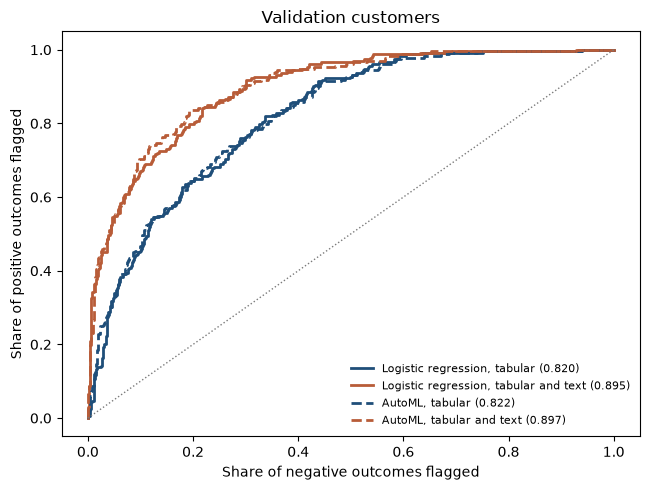

In [14]:
automl.plot_roc(state["probabilities"])

`plot_calibration(state["probabilities"])` takes the same table. It returns a figure: mean predicted probability against the share of those customers with `OBSERVED_COLUMN` equal to `1`.

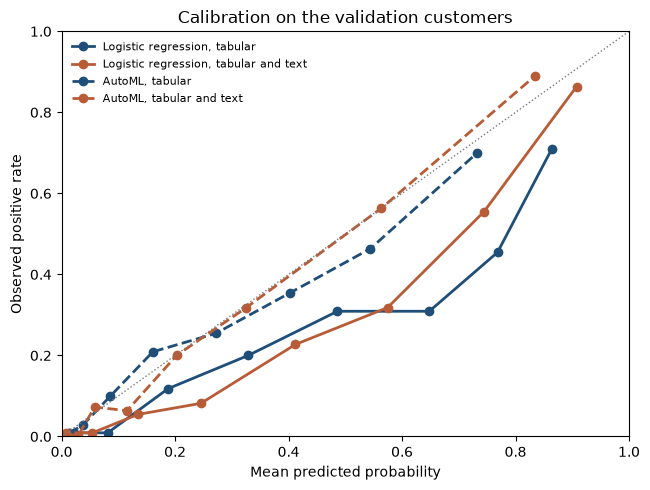

In [15]:
automl.plot_calibration(state["probabilities"])

On the telco file the four scores are already present, so the displays compare all four. A comparison file with no Gemini column shows the two logistic models. After a paid run, run the three cells again. Compare tabular logistic regression with tabular Gemini. Separately, compare the communications logistic regression with Gemini plus `TEXT_FEATURE`. The table is the result.

### Does the campaign decision change?

The calculation uses `p1`, `cost`, `loss` and `BUDGET`. Only the churn score changes: once `p_logistic_tabular`, once `p_logistic_text`, and, when those columns exist, once `p_automl_tabular` and once `p_automl_text`.

The Chapter 6 rule is unchanged. Target the customer when the expected loss avoided by the campaign is larger than `cost`.



In [16]:
summary = automl.economic_table(state["probabilities"])
summary

,Model,ROC-AUC,Customers targeted,Campaign spend,Expected cost,Expected net benefit,Budget customers,Budget spend,Budget expected cost,Budget expected net benefit
0,"Logistic regression, tabular",0.820054,538,23040.0,233372.266154,91362.638202,237,7995.0,255610.035183,69124.869173
1,"Logistic regression, tabular and text",0.894581,479,18330.0,238083.479445,58867.421539,236,7995.0,249481.647192,47469.253791
2,"AutoML, tabular",0.821686,249,9495.0,195439.902452,25215.153356,217,7995.0,195674.725847,24980.329961
3,"AutoML, tabular and text",0.897208,162,6450.0,188918.511315,20365.231049,162,6450.0,188918.511315,20365.231049


`Expected cost` and `Expected net benefit` use the score as $p_0$. Logistic regression and the Gemini search are fitted to the probabilities of the outcome. They are not fitted to this cost. A higher score raises $b_i = L_i(p_{0,i} - p_{1,i}) - c_i$. The smallest expected cost is then a property of those estimated probabilities. It is not a reason to prefer the model.

`realized_cost_table(state["probabilities"])` keeps `p1`, `cost` and `loss` fixed and reads `OBSERVED_COLUMN`. With no campaign, a customer who left costs `loss` and a customer who stayed costs 0. The contact list is still the Chapter 6 list for that score. For a selected customer who left, `loss` is replaced by `cost + loss * p1`. For a selected customer who stayed, the cost is `cost`. `Net benefit` is the no-campaign total minus the with-campaign total. The budget columns use the contact list that respects `BUDGET`. `p1` is held as given. The table accounts for the historical outcomes under that fixed `p1`. It does not measure the effect of a campaign.

In [17]:
automl.realized_cost_table(state["probabilities"])

,Model,Cost without campaign,Leavers contacted,Stayers contacted,Cost with campaign,Net benefit,Budget leavers contacted,Budget stayers contacted,Budget cost with campaign,Budget net benefit
0,"Logistic regression, tabular",204510.6,167,371,153280.862284,51229.737716,81,156,169601.943111,34908.656889
1,"Logistic regression, tabular and text",204510.6,204,275,138586.144367,65924.455633,137,99,153873.672003,50636.927997
2,"AutoML, tabular",204510.6,81,168,173751.073937,30759.526063,75,142,176006.901150,28503.698850
3,"AutoML, tabular and text",204510.6,120,42,164523.474851,39987.125149,120,42,164523.474851,39987.125149


The probability summaries and `realized_cost_table` answer two questions.

ROC-AUC, PR-AUC, log-loss, the Brier score and the calibration plot ask whether the score orders the customers and matches the share who left. On these comparison rows, the Gemini model that uses `TEXT_FEATURE` is ahead on those four summaries. The logistic model with the communications is close behind it. The two tabular models follow both.

`realized_cost_table` asks the Chapter 6 question. The score only builds the contact list, through $L_i(p_{0,i} - p_{1,i}) > c_i$. The money is then computed from who left, with `p1` held fixed. On this file the communications logistic contacts 204 leavers and 275 stayers, and its net benefit is the largest, about 66,000. The Gemini model with text contacts 120 leavers and 42 stayers. That list is more concentrated on leavers. Its net benefit is smaller, about 40,000, because more of the historical leavers are left uncontacted and each of them still costs `loss`. The same order remains under `BUDGET`.

Chapter 6 is the step between the two readings. A gain in ROC-AUC does not name the customers worth a contact. The loss, the contact cost and `p1` can place two customers with the same score on opposite sides of the rule. The realized table is that rule applied to the people who left in this comparison set.

Use that table when the customers about to be contacted resemble these comparison rows, and when `p1`, `cost` and `loss` stay the ones used here. The overlap between a contact list and the historical leavers is a fact about this cohort. It is the relevant business comparison for a cohort of the same kind.

A cohort with a different churn share, different losses, or a different effect of a contact need not repeat that overlap. The Chapter 6 rule is then applied again, to new scores and to the new costs. The model that estimates the probabilities well is the more reliable input to that rule. A list that caught the leavers of this particular sample is tied to this sample.

`p1` remains an assumption. The realized net benefit accounts for these historical outcomes under that assumption. It compares the contact lists on this cohort. It is not a measured effect of a campaign, and it is not a forecast for a cohort that does not look like this one.

### Delete the cloud resources

When `validation_probabilities.csv` has the Gemini columns, the campaign calculation does not need the cloud model.

`cleanup_cloud(approve_delete=True)` runs only when `DELETE_CLOUD_RESOURCES` is `True`. It also requires `AUTOML_APPROVE_DELETE=yes`. It reads `cloud_resources.json` in `OUTPUT_DIR`, the names `run_cloud()` recorded. It returns `0` when nothing remains or the deletion finished, and `2` when the approval is missing.

In [18]:
DELETE_CLOUD_RESOURCES = False

if DELETE_CLOUD_RESOURCES:
    os.environ["AUTOML_APPROVE_DELETE"] = "yes"
    automl.cleanup_cloud(approve_delete=True)
else:
    os.environ["AUTOML_APPROVE_DELETE"] = "no"
    print("Nothing was deleted.")

Nothing was deleted.


From the terminal:

```bash
export AUTOML_APPROVE_DELETE=yes
python python/workshop_automl.py cleanup --approve-delete
```

The paid run also writes `cleanup_commands.sh` in `OUTPUT_DIR`. Then list the project:

```bash
gcloud ai endpoints list --region="$GOOGLE_CLOUD_REGION"
gcloud ai models list --region="$GOOGLE_CLOUD_REGION"
gcloud ai datasets list --region="$GOOGLE_CLOUD_REGION"
# GCS_PREFIX is the folder set in the lesson. The example is telco-automl.
export GCS_PREFIX=telco-automl
gcloud storage ls "gs://$GOOGLE_CLOUD_BUCKET/$GCS_PREFIX/**"
```

This lesson does not create an endpoint. If one is listed, billing continues until each deployed model is removed.

```bash
gcloud ai endpoints describe ENDPOINT_ID --region="$GOOGLE_CLOUD_REGION"
gcloud ai endpoints undeploy-model ENDPOINT_ID \
  --deployed-model-id=DEPLOYED_MODEL_ID \
  --region="$GOOGLE_CLOUD_REGION" --quiet
gcloud ai endpoints delete ENDPOINT_ID --region="$GOOGLE_CLOUD_REGION" --quiet
```

To stop a job that is still running:

```bash
gcloud ai training-pipelines cancel TRAINING_PIPELINE_ID --region="$GOOGLE_CLOUD_REGION" --quiet
gcloud ai batch-prediction-jobs cancel BATCH_JOB_ID --region="$GOOGLE_CLOUD_REGION" --quiet
```